In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
dataset = pd.read_csv('Mall_Customersnew.csv')


In [3]:
dataset

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [4]:
X = dataset.iloc[:, 3:5].values

In [5]:
X

array([[15, 39],
       [15, 81],
       [16,  6],
       [16, 77],
       [17, 40],
       [17, 76],
       [18,  6],
       [18, 94],
       [19,  3],
       [19, 72],
       [19, 14],
       [19, 99],
       [20, 15],
       [20, 77],
       [20, 13],
       [20, 79],
       [21, 35],
       [21, 66],
       [23, 29],
       [23, 98],
       [24, 35],
       [24, 73],
       [25,  5],
       [25, 73],
       [28, 14],
       [28, 82],
       [28, 32],
       [28, 61],
       [29, 31],
       [29, 87],
       [30,  4],
       [30, 73],
       [33,  4],
       [33, 92],
       [33, 14],
       [33, 81],
       [34, 17],
       [34, 73],
       [37, 26],
       [37, 75],
       [38, 35],
       [38, 92],
       [39, 36],
       [39, 61],
       [39, 28],
       [39, 65],
       [40, 55],
       [40, 47],
       [40, 42]])

C:\Users\bkmad\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\bkmad\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\bkmad\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\bkmad\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

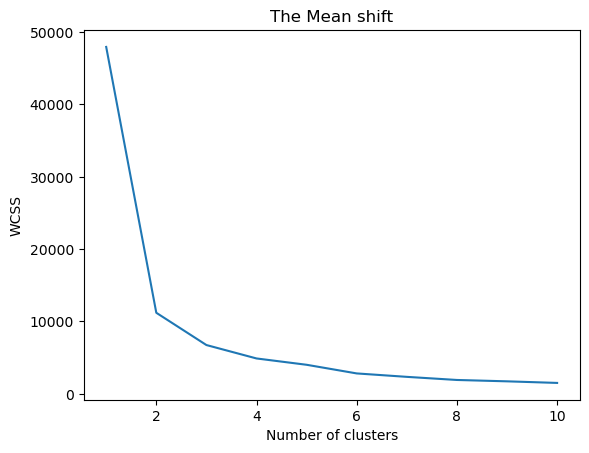

In [6]:
from sklearn.cluster import KMeans
list1 = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters = i, init = 'k-means++', random_state = 42)
    kmeans.fit(X)
    list1.append(kmeans.inertia_)
plt.plot(range(1, 11), list1)
plt.title('The Mean shift')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

In [7]:
list1

[47955.38775510204,
 11202.458333333334,
 6740.640786749484,
 4886.083333333333,
 4011.6785714285716,
 2816.2119047619044,
 2342.0619047619048,
 1911.1999999999998,
 1723.4714285714285,
 1503.304761904762]

In [9]:
#from sklearn.cluster import MeanShift
#kmeans = MeanShift(n_clusters = 5, init = 'k-means++', random_state = 42)
#y_kmeans = kmeans.fit_predict(X)

from sklearn.cluster import MeanShift
kmeans=MeanShift(bandwidth=2).fit(X)
#kmeans = MeanShift(bandwith=2, random_state=0).fit(X)
#kmeans = MeanShift(n_clusters=2, random_state=0).fit(X)
#kmeans = MeanShift(n_clusters = 5,random_state=0).fit(X)
y_kmeans = kmeans.fit_predict(X)
#y_MS=MS.fit_predict(X)

In [10]:
y_kmeans

array([40, 39,  5,  6, 38,  6,  5, 37, 36, 35,  0, 34,  0,  4,  0,  4, 33,
       32, 31, 30, 29,  3, 28,  3, 27, 25,  2, 26,  2, 24, 23, 22, 21, 18,
       20, 19, 17, 16, 15, 14,  1, 13,  1, 11, 12, 10,  7,  8,  9])

In [11]:
supervised=dataset

In [12]:
supervised

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [13]:
supervised['Cluster_group']=y_kmeans

In [14]:
supervised

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster_group
0,1,Male,19,15,39,40
1,2,Male,21,15,81,39
2,3,Female,20,16,6,5
3,4,Female,23,16,77,6
4,5,Female,31,17,40,38
5,6,Female,22,17,76,6
6,7,Female,35,18,6,5
7,8,Female,23,18,94,37
8,9,Male,64,19,3,36
9,10,Female,30,19,72,35


In [15]:
supervised.to_csv("cluster.csv",index=False)

In [16]:
dir(kmeans)

['__annotations__',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__firstlineno__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__setstate__',
 '__sizeof__',
 '__sklearn_clone__',
 '__sklearn_tags__',
 '__static_attributes__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_build_request_for_signature',
 '_doc_link_module',
 '_doc_link_template',
 '_doc_link_url_param_generator',
 '_estimator_type',
 '_get_default_requests',
 '_get_doc_link',
 '_get_metadata_request',
 '_get_param_names',
 '_get_params_html',
 '_html_repr',
 '_parameter_constraints',
 '_repr_html_',
 '_repr_html_inner',
 '_repr_mimebundle_',
 '_validate_params',
 'bandwidth',
 'bin_seeding',
 'cluster_all',
 'cluster_centers_',
 'fit',
 'fit_predict',
 'get_metadata_routing',
 'get_

In [17]:
centroids=kmeans.cluster_centers_

In [18]:
centroids

array([[19.66666667, 14.        ],
       [38.5       , 35.5       ],
       [28.5       , 31.5       ],
       [24.5       , 73.        ],
       [20.        , 78.        ],
       [17.        ,  6.        ],
       [16.5       , 76.5       ],
       [40.        , 55.        ],
       [40.        , 47.        ],
       [40.        , 42.        ],
       [39.        , 65.        ],
       [39.        , 61.        ],
       [39.        , 28.        ],
       [38.        , 92.        ],
       [37.        , 75.        ],
       [37.        , 26.        ],
       [34.        , 73.        ],
       [34.        , 17.        ],
       [33.        , 92.        ],
       [33.        , 81.        ],
       [33.        , 14.        ],
       [33.        ,  4.        ],
       [30.        , 73.        ],
       [30.        ,  4.        ],
       [29.        , 87.        ],
       [28.        , 82.        ],
       [28.        , 61.        ],
       [28.        , 14.        ],
       [25.        ,

In [19]:
y_kmeans

array([40, 39,  5,  6, 38,  6,  5, 37, 36, 35,  0, 34,  0,  4,  0,  4, 33,
       32, 31, 30, 29,  3, 28,  3, 27, 25,  2, 26,  2, 24, 23, 22, 21, 18,
       20, 19, 17, 16, 15, 14,  1, 13,  1, 11, 12, 10,  7,  8,  9])

In [20]:
supervised.columns[3]

'Annual Income (k$)'

In [21]:
supervised.columns

Index(['CustomerID', 'Genre', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)', 'Cluster_group'],
      dtype='object')

C:\Users\bkmad\anaconda3\Lib\site-packages\seaborn\regression.py:598: UserWarning: legend_out is deprecated from the `lmplot` function signature. Please update your code to pass it using `facet_kws`.
  warnings.warn(msg, UserWarning)


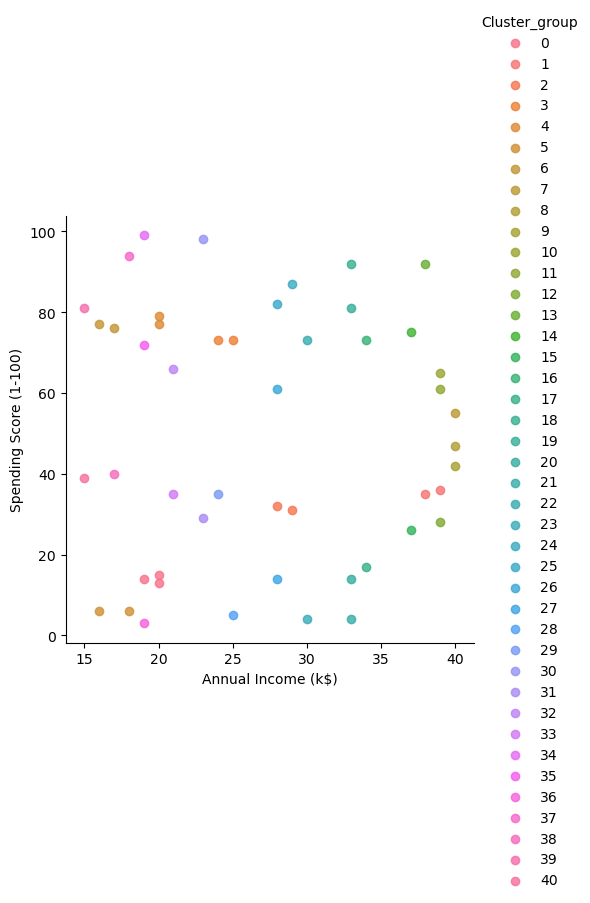

In [22]:
import seaborn as sns
facet = sns.lmplot(data=supervised, x=supervised.columns[3], y=supervised.columns[4], hue=supervised.columns[5], 
                   fit_reg=False, legend=True, legend_out=True)

C:\Users\bkmad\anaconda3\Lib\site-packages\seaborn\regression.py:598: UserWarning: legend_out is deprecated from the `lmplot` function signature. Please update your code to pass it using `facet_kws`.
  warnings.warn(msg, UserWarning)


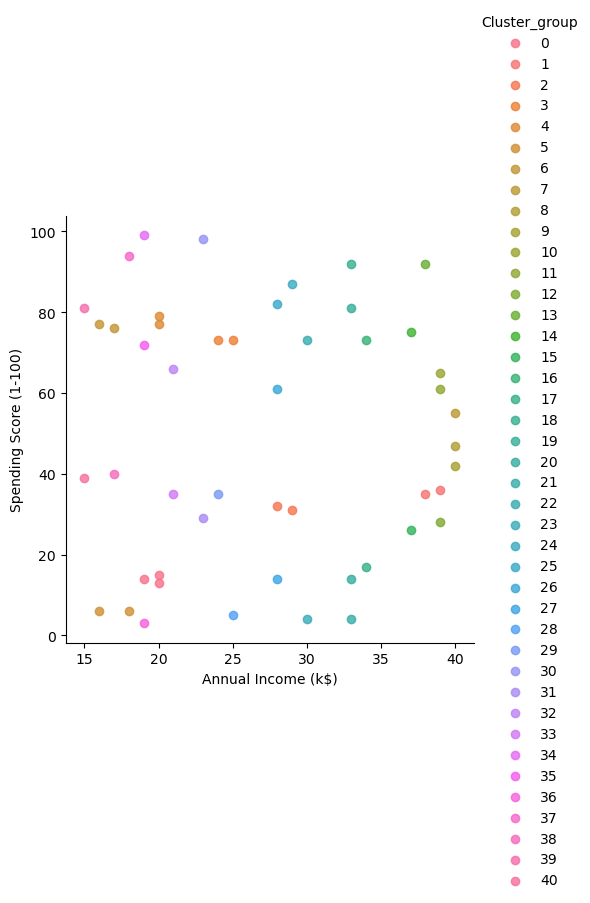

In [23]:
import seaborn as sns
facet = sns.lmplot(data=supervised, x=supervised.columns[3], y=supervised.columns[4], hue=supervised.columns[5],
                   fit_reg=False,legend_out=True)

In [ ]:
#!pip install seaborn